# Dephasing, phase retrieval, and the road from classroom to instrument
### classical → quantum information, one SymPy derivation at a time, plus a long-term plan you can edit

**In plain words.** A light detector, and a qubit measured the ordinary way, both report only
*how much*, never *which phase*. Phase can be **lost** (dephasing: the environment scrambles it)
or **hidden but recoverable** (apply a known transformation first, then measure). Jalali's
time-stretch instruments use the second idea with optical dispersion. Quantum state tomography
uses it with qubit rotations. This notebook shows they are the same mathematics, then plans a
path from undergraduate courses to a working instrument.

**Accessibility choices in this notebook:**
* every plot uses the Okabe–Ito colorblind-safe palette;
* color is never the only cue: plots also use line style, markers, or labels;
* each figure has a printed text description (alt text);
* each section opens with a plain-language summary.

Synthetic data only. Durations and dollar figures in §7 are editable planning assumptions.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import dephasing_phase_retrieval as dp
from dgs import qis_pathway_planning as q
from dgs import gs_core
sp.init_printing()
C = dp.OKABE_ITO
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=[C[k] for k in ("blue", "vermillion", "green", "orange", "purple", "sky")]),
                     "font.size": 11})

## 1. The instrument flow diagram

**In plain words.** The top row is a time-stretch instrument and the bottom row is a qubit
experiment. Stages joined by dotted arrows do the same mathematical job.

The key stage is the third box. In a Jalali-style instrument, dispersion
$H(f)=e^{j\pi Df^2}$ is a **known, diagonal unitary in the frequency basis**. The photodiode
then measures in the **time basis**. Tomography applies a known rotation and then measures in
the Z basis. Both are "scramble the phase into intensity in a way you know, then measure
intensity".

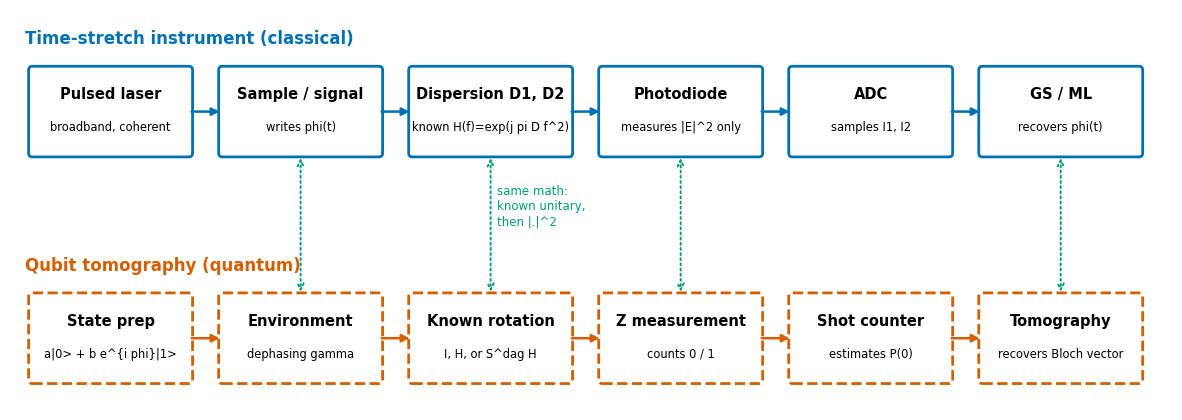

Figure description: Two six-stage flow diagrams, one above the other. Top, classical: pulsed laser, sample writes phase, known dispersion D1 and D2, photodiode measures intensity only, ADC, Gerchberg-Saxton or ML recovers phase. Bottom, quantum: state preparation, dephasing environment, known rotation, Z measurement, shot counter, tomography recovers the Bloch vector. Dotted double arrows link sample to environment, dispersion to rotation, photodiode to Z measurement, and GS to tomography.


In [2]:
fig, alt = dp.flow_diagram()
plt.show()
print("Figure description:", alt)

## 2. Quantum dephasing, derived in SymPy

**In plain words.** Dephasing erases phase information, the off-diagonal entry of the density
matrix, but leaves the populations untouched.

Start from $|\psi\rangle=a|0\rangle+b\,e^{i\phi}|1\rangle$ and apply the Lindblad equation with
$L=\sqrt{\gamma/2}\,\sigma_z$:

In [3]:
rho12, drho11, sx = dp.dephasing_symbolic()
display(sp.Eq(sp.Symbol("rho_12(t)"), rho12), sp.Eq(sp.Symbol("drho_11/dt"), drho11), sp.Eq(sp.Symbol("<sigma_x>(t)"), sx))

The phase $\phi$ survives only inside $\rho_{12}$, and $\rho_{12}$ decays as $e^{-\gamma t}$.
A Z measurement reads $\rho_{11}$, which doesn't depend on $\phi$ at all.

## 3. Rotate, then measure: tomography

**In plain words.** A Z measurement sees one axis of the Bloch sphere. To see the other two,
rotate the qubit by a known amount first.

SymPy computes $P(0)$ after each pre-rotation:

In [4]:
for k, v in dp.measurement_probabilities_symbolic().items():
    display(sp.Eq(sp.Symbol(f"P(0) [{k}]"), v))

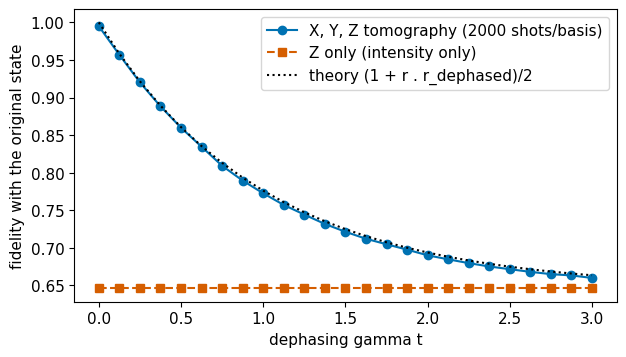

Figure description: fidelity versus dephasing. Full tomography (circles, solid) starts near 1 and falls toward the Z-only line (squares, dashed), which stays flat near 0.65 because Z alone never sees the phase. A dotted black theory curve overlays the circles.


In [5]:
r = dp.bloch_from_angles(1.0, 0.7)
gts = np.linspace(0, 3, 25)
full = [np.mean([dp.state_fidelity(r, dp.tomography(dp.dephase_bloch(r, g), 2000, rng=s)) for s in range(10)]) for g in gts]
zonly = [np.mean([dp.state_fidelity(r, dp.tomography(dp.dephase_bloch(r, g), 2000, "Z", rng=s)) for s in range(10)]) for g in gts]
theory = [dp.state_fidelity(r, dp.dephase_bloch(r, g)) for g in gts]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(gts, full, "o-", label="X, Y, Z tomography (2000 shots/basis)")
ax.plot(gts, zonly, "s--", label="Z only (intensity only)")
ax.plot(gts, theory, "k:", label="theory (1 + r . r_dephased)/2")
ax.set_xlabel("dephasing gamma t"); ax.set_ylabel("fidelity with the original state"); ax.legend(); plt.show()
print("Figure description: fidelity versus dephasing. Full tomography (circles, solid) starts near 1 and falls "
      "toward the Z-only line (squares, dashed), which stays flat near", round(zonly[0], 2),
      "because Z alone never sees the phase. A dotted black theory curve overlays the circles.")

Two separate failures show up here:
* **Z only** is blind to phase from the start. More shots don't help, because the information isn't in the data.
* **Dephasing** removes the phase from the state itself. Better measurements can't recover it,
  because the information no longer exists.

## 4. The classical version: phase noise vs dispersion-assisted phase retrieval

**In plain words.** The same two failures happen in a time-stretch instrument. Dispersion plus
Gerchberg–Saxton (the repo's `gs_core`) recovers the phase. Random phase jitter from pulse to
pulse washes out the interference fringes that carry it.

For Gaussian phase noise of standard deviation $\sigma$, the coherence factor is
$|\langle e^{i\delta}\rangle|=e^{-\sigma^2/2}$. This plays the role of $e^{-\gamma t}$:

In [6]:
s = sp.symbols("sigma", positive=True); d = sp.symbols("delta", real=True)
char = sp.integrate(sp.exp(sp.I*d) * sp.exp(-d**2/(2*s**2)) / sp.sqrt(2*sp.pi*s**2), (d, -sp.oo, sp.oo))
display(sp.Eq(sp.Symbol("<e^{i delta}>"), sp.simplify(char)))

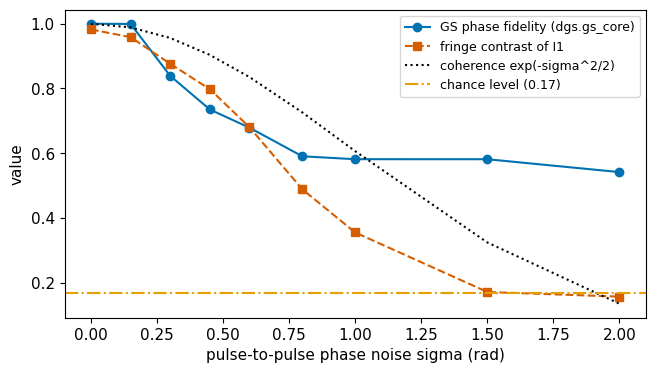

sigma=0.00  fidelity=1.000  contrast=0.982
sigma=0.15  fidelity=0.999  contrast=0.959
sigma=0.30  fidelity=0.839  contrast=0.876
sigma=0.45  fidelity=0.735  contrast=0.798
sigma=0.60  fidelity=0.679  contrast=0.680
sigma=0.80  fidelity=0.591  contrast=0.489
sigma=1.00  fidelity=0.582  contrast=0.355
sigma=1.50  fidelity=0.582  contrast=0.172
sigma=2.00  fidelity=0.542  contrast=0.157
Figure description: phase-retrieval fidelity (circles, solid) and fringe contrast (squares, dashed) both fall as phase noise grows, following the dotted coherence curve. Fidelity flattens near the dash-dot chance level, where the retrieved phase is no better than an unrelated random phase.


In [7]:
sig = [0.0, 0.15, 0.3, 0.45, 0.6, 0.8, 1.0, 1.5, 2.0]
out = dp.retrieval_vs_dephasing(sig, n_realizations=40, n_iter=100)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(out["sigma"], out["fidelity"], "o-", label="GS phase fidelity (dgs.gs_core)")
ax.plot(out["sigma"], out["contrast"], "s--", label="fringe contrast of I1")
ax.plot(out["sigma"], out["coherence"], "k:", label="coherence exp(-sigma^2/2)")
ax.axhline(out["chance"], color=C["orange"], ls="-.", label=f"chance level ({out['chance']:.2f})")
ax.set_xlabel("pulse-to-pulse phase noise sigma (rad)"); ax.set_ylabel("value"); ax.legend(fontsize=9); plt.show()
for a, b, c_ in zip(out["sigma"], out["fidelity"], out["contrast"]):
    print(f"sigma={a:4.2f}  fidelity={b:.3f}  contrast={c_:.3f}")
print("Figure description: phase-retrieval fidelity (circles, solid) and fringe contrast (squares, dashed) "
      "both fall as phase noise grows, following the dotted coherence curve. Fidelity flattens near the "
      "dash-dot chance level, where the retrieved phase is no better than an unrelated random phase.")

Read this plot the way you read the tomography plot:
* with no noise, two dispersions (the classical counterpart of rotations) recover $\phi(t)$ to fidelity ≈ 1;
* as $\sigma$ grows, the averaged intensity loses its fringes and retrieval fails, no matter how many iterations run.

**What the instrument designer should take from this:** phase diversity can't create information
that dephasing has destroyed. Laser coherence and pulse-to-pulse stability are prerequisites for
phase retrieval, not optional upgrades.

## 5. One dictionary

| quantum (QIS) | classical (time-stretch) |
|---|---|
| state $\rho$ | field $E(t)$ |
| populations $\rho_{ii}$ | intensity $|E(t)|^2$ |
| coherence $\rho_{12}$ | interference fringes / spectral phase |
| dephasing $e^{-\gamma t}$ | phase-noise coherence $e^{-\sigma^2/2}$ |
| known rotation (H, S†H) | known dispersion $e^{j\pi Df^2}$ |
| Z measurement | photodiode |
| tomography (linear inversion) | Gerchberg–Saxton (iterative projections) |
| shot noise $\propto 1/\sqrt{N}$ | detector/ADC noise, averaging over pulses |

## 6. Undergraduate pathway: classical computing → QIS

**In plain words.** The topics are arranged by prerequisite. Everything in one column can be
studied in parallel, and every topic links to a module in this repo that already teaches it.

The pathway is a **directed acyclic graph**. A topological sort (Kahn's algorithm) gives a valid
order, and grouping topics by longest-path depth gives the columns.

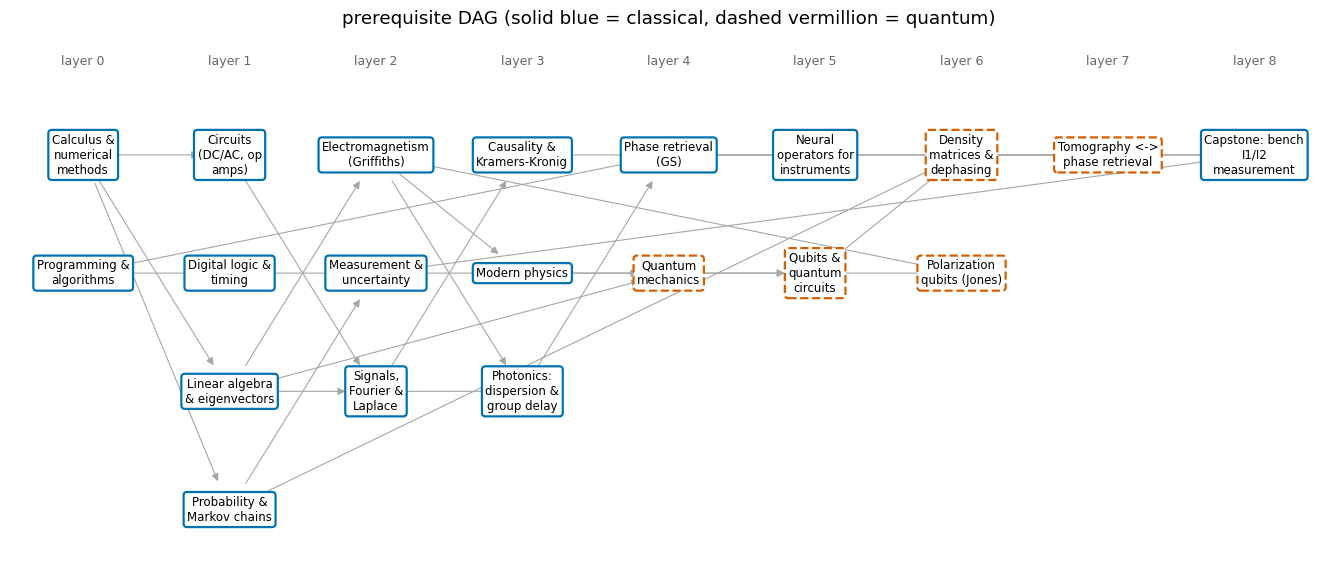

layer 0: Calculus & numerical methods [dgs.numerical_methods]; Programming & algorithms [dgs.algorithms]
layer 1: Circuits (DC/AC, op amps) [dgs.opamp_inverting]; Digital logic & timing [dgs.logic_timing]; Linear algebra & eigenvectors [dgs.complex_eigen_bridge]; Probability & Markov chains [dgs.markov]
layer 2: Electromagnetism (Griffiths) [griffiths.electrodynamics]; Measurement & uncertainty [dgs.error_propagation]; Signals, Fourier & Laplace [dgs.fourier_tools]
layer 3: Causality & Kramers-Kronig [dgs.causality]; Modern physics [dgs.planck_quantization_taylor]; Photonics: dispersion & group delay [dgs.pulse_moments_group_delay]
layer 4: Phase retrieval (GS) [dgs.gs_core]; Quantum mechanics [dgs.ehrenfest_theorem]
layer 5: Neural operators for instruments [dgs.gs_fno]; Qubits & quantum circuits [dgs.qubits]
layer 6: Density matrices & dephasing [dgs.cell_hilbert_bridge]; Polarization qubits (Jones) [dgs.polarization_qubit]
layer 7: Tomography <-> phase retrieval [dgs.dephasing_phase


all linked modules import: True


In [8]:
import textwrap
L = q.layers(q.PATHWAY)
pos = {k: (2.2 * i, -1.25 * j) for i, layer in enumerate(L) for j, k in enumerate(layer)}
fig, ax = plt.subplots(figsize=(17, 7))
for k, (pre, mod) in q.PATHWAY.items():
    for p in pre:
        ax.annotate("", pos[k], pos[p], arrowprops=dict(arrowstyle="-|>", color="0.65", lw=0.8, shrinkA=22, shrinkB=22))
quantum_words = ("Qubit", "Polarization", "Density", "Tomography", "Quantum")
for k, (x, y) in pos.items():
    isq = any(w in k for w in quantum_words)
    ax.text(x, y, textwrap.fill(k, 15, break_long_words=False), ha="center", va="center", fontsize=8.5,
            bbox=dict(boxstyle="round", fc="white", ec=C["vermillion"] if isq else C["blue"], lw=1.6, ls="--" if isq else "-"))
for i in range(len(L)):
    ax.text(2.2 * i, 0.95, f"layer {i}", ha="center", fontsize=9, color="0.4")
ax.set_xlim(-1.1, 2.2 * (len(L) - 1) + 1.1); ax.set_ylim(-4.4, 1.3); ax.axis("off")
ax.set_title("prerequisite DAG (solid blue = classical, dashed vermillion = quantum)"); plt.show()
for i, layer in enumerate(L):
    print(f"layer {i}: " + "; ".join(f"{k} [{q.PATHWAY[k][1] or 'bench work'}]" for k in layer))
print("\nall linked modules import:", all(q.module_available(m) for _, m in q.PATHWAY.values()))

The depth is 9 layers. If each layer takes about one term, that's roughly three years, which
matches a three-year self-paced plan. The capstone is the real bench I1/I2 measurement; everything
else in the repo is preparation for it.

## 7. Entrepreneurship: a TRL roadmap with a critical path

**In plain words.** A startup plan is also a DAG. Its **critical path**, the longest chain of
dependent steps, sets the earliest finish date. Speeding up anything off that path doesn't move
the finish date.

The milestones climb the Technology Readiness Level ladder:

In [9]:
for k, v in q.TRL_LADDER.items():
    print(f"TRL {k}: {v}")

TRL 1: basic principles observed
TRL 2: concept formulated
TRL 3: proof of concept (analysis/simulation)
TRL 4: validated in lab
TRL 5: validated in relevant environment (components)
TRL 6: prototype demonstrated in relevant environment
TRL 7: prototype in operational environment
TRL 8: system complete and qualified
TRL 9: proven in operation


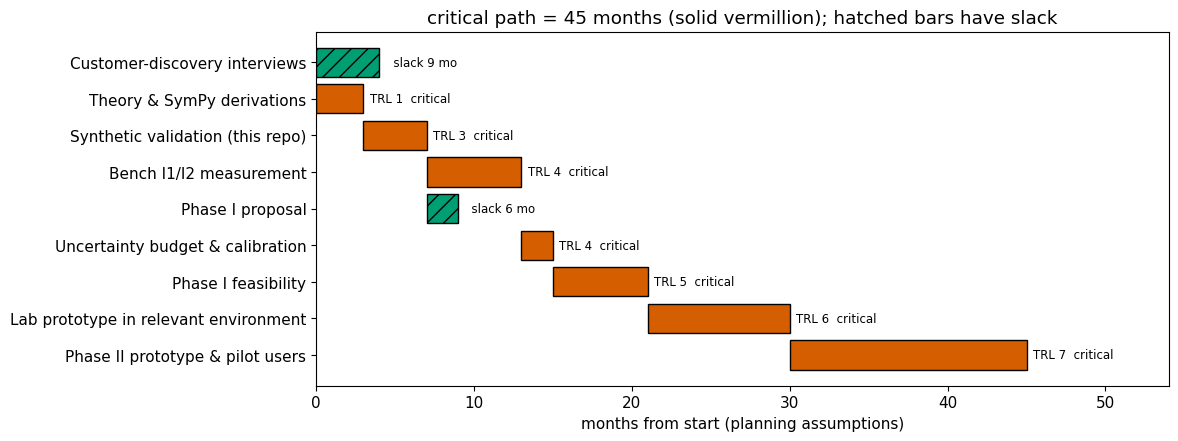

Critical path: Theory & SymPy derivations -> Synthetic validation (this repo) -> Bench I1/I2 measurement -> Uncertainty budget & calibration -> Phase I feasibility -> Lab prototype in relevant environment -> Phase II prototype & pilot users
Figure description: Gantt chart of nine milestones. Solid bars are on the critical path, which runs from theory through the bench measurement, calibration, Phase I, lab prototype, and Phase II. Hatched bars (customer discovery, Phase I proposal) have slack.


In [10]:
total, path, finish = q.critical_path()
sl = q.slack()
order = q.topological_order(q.ROADMAP)
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, k in enumerate(order):
    dur, kind = q.ROADMAP[k][1], q.ROADMAP[k][3]
    crit = k in path
    ax.barh(i, dur, left=finish[k] - dur, color=C["vermillion"] if crit else (C["sky"] if kind == "tech" else C["green"]),
            hatch="" if crit else "//", edgecolor="black")
    trl = q.ROADMAP[k][2]
    ax.text(finish[k] + 0.4, i, (f"TRL {trl}" if trl else "") + (f"  slack {sl[k]} mo" if sl[k] else "  critical"), va="center", fontsize=8.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("months from start (planning assumptions)"); ax.set_xlim(0, total + 9)
ax.set_title(f"critical path = {total} months (solid vermillion); hatched bars have slack"); plt.show()
print("Critical path:", " -> ".join(path))
print("Figure description: Gantt chart of nine milestones. Solid bars are on the critical path, which runs from "
      "theory through the bench measurement, calibration, Phase I, lab prototype, and Phase II. Hatched bars "
      "(customer discovery, Phase I proposal) have slack.")

What the plan says:
* The **bench I1/I2 measurement is on the critical path**. Every month it slips moves the end date.
  That makes it the highest-leverage task, for the education plan and the venture plan alike.
* **Customer discovery has 9 months of slack**, so it can run in parallel from day one. Start it
  early anyway: interviews are what tell you whether the instrument is worth building.
* Budget assumptions from your earlier notes (verify against the current solicitation; caps change):

In [11]:
for k, v in q.PLANNING_BUDGET.items():
    print(f"{k:9s} ${v:,}")
print(f"Phase I per person if split across 3: ${q.PLANNING_BUDGET['Phase I']/3:,.0f}")

Phase I   $275,000
Phase II  $1,750,000
Phase I per person if split across 3: $91,667


## 8. Inclusive design: the checklist, applied to the instrument and the team

**In plain words.** These are concrete practices that make the work usable by more people.
They cost almost nothing when planned early.

* **Figures:** a colorblind-safe palette, redundant line styles and markers, and text descriptions (this notebook).
* **Instrument readouts:** never use red/green alone for status. Pair color with a shape, a label,
  or an audible tone, and make on-screen text resizable.
* **Documentation:** plain-language summaries before the math, units on every axis, and runnable
  examples. Readers coming from community college, a transfer, or a career change start from the same page.
* **Team and customers:** run customer-discovery interviews with the people who will actually
  operate the instrument, not only the people who buy it. Budget for accessibility from the start;
  retrofitting it later costs more.
* **Data:** synthetic or authorized data only. Get consent and institutional review for anything
  involving people.

*All results are synthetic. Plans and dollar amounts are user-editable assumptions, not commitments or facts about any program.*